In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Environment ready!")

Environment ready!


In [2]:
train_path = "../data/raw/UNSW_NB15_training-set.csv"
test_path = "../data/raw/UNSW_NB15_testing-set.csv"

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

Training shape: (175341, 45)
Testing shape: (82332, 45)


In [3]:
train_path = "../data/raw/UNSW_NB15_training-set.csv"
test_path = "../data/raw/UNSW_NB15_testing-set.csv"

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

Training shape: (175341, 45)
Testing shape: (82332, 45)


In [4]:
print(train_df.columns.tolist())

['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']


In [5]:
train_df.head()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [6]:
train_df["attack_cat"].value_counts()

attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64

In [7]:
train_df["label"].value_counts()

label
1    119341
0     56000
Name: count, dtype: int64

In [8]:
train_df.isnull().sum().sum()

np.int64(0)

In [9]:
test_df.isnull().sum().sum()

np.int64(0)

In [10]:
train_df.drop(columns=["id"]).duplicated().sum()

np.int64(67601)

In [11]:
test_df.drop(columns=["id"]).duplicated().sum()

np.int64(26387)

In [12]:
cols = train_df.columns.drop("id")

train_unique = train_df[cols].drop_duplicates()
test_unique = test_df[cols].drop_duplicates()

overlap = pd.merge(train_unique, test_unique, on=list(cols))

print("Shared unique records:", len(overlap))

Shared unique records: 940


In [13]:
train_df.dtypes.value_counts()

int64      30
float64    11
str         4
Name: count, dtype: int64

In [14]:
train_df.select_dtypes(exclude="number").columns.tolist()

['proto', 'service', 'state', 'attack_cat']

In [15]:
train_df[["proto", "service", "state"]].nunique()

proto      133
service     13
state        9
dtype: int64

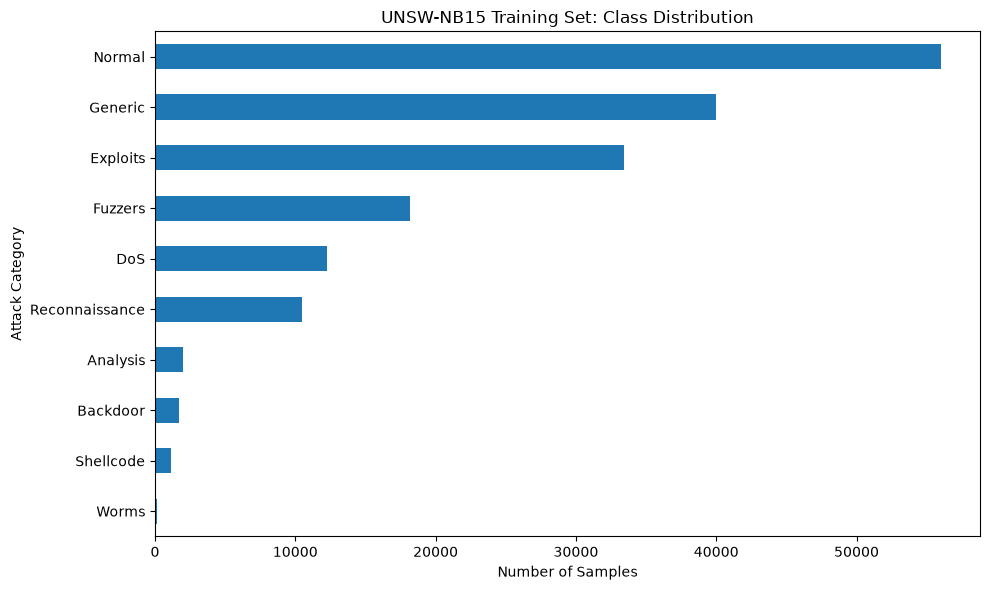

In [16]:
counts = train_df["attack_cat"].value_counts().sort_values()

plt.figure(figsize=(10, 6))
counts.plot(kind="barh")

plt.title("UNSW-NB15 Training Set: Class Distribution")
plt.xlabel("Number of Samples")
plt.ylabel("Attack Category")
plt.tight_layout()
plt.show()

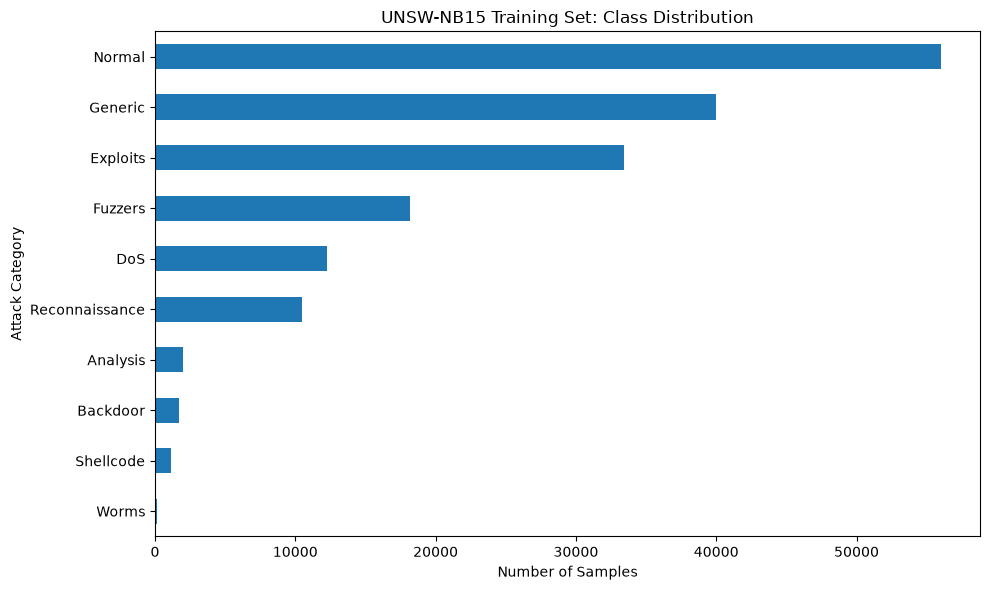

Figure saved successfully!


In [17]:
from pathlib import Path

output_dir = Path("../results/figures")
output_dir.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(10, 6))
counts.plot(kind="barh", ax=ax)

ax.set_title("UNSW-NB15 Training Set: Class Distribution")
ax.set_xlabel("Number of Samples")
ax.set_ylabel("Attack Category")

fig.tight_layout()
fig.savefig(output_dir / "class_distribution.png", dpi=300)

plt.show()

print("Figure saved successfully!")

In [18]:
test_df["attack_cat"].value_counts()

attack_cat
Normal            37000
Generic           18871
Exploits          11132
Fuzzers            6062
DoS                4089
Reconnaissance     3496
Analysis            677
Backdoor            583
Shellcode           378
Worms                44
Name: count, dtype: int64

In [19]:
pd.crosstab(train_df["attack_cat"], train_df["label"])

label,0,1
attack_cat,,
Analysis,0,2000
Backdoor,0,1746
DoS,0,12264
Exploits,0,33393
Fuzzers,0,18184
Generic,0,40000
Normal,56000,0
Reconnaissance,0,10491
Shellcode,0,1133


In [20]:
pd.crosstab(test_df["attack_cat"], test_df["label"])

label,0,1
attack_cat,,
Analysis,0,677
Backdoor,0,583
DoS,0,4089
Exploits,0,11132
Fuzzers,0,6062
Generic,0,18871
Normal,37000,0
Reconnaissance,0,3496
Shellcode,0,378


In [21]:
train_df["service"].value_counts(dropna=False)

service
-           94168
dns         47294
http        18724
smtp         5058
ftp-data     3995
ftp          3428
ssh          1302
pop3         1105
dhcp           94
snmp           80
ssl            56
irc            25
radius         12
Name: count, dtype: int64

In [22]:
test_df["service"].value_counts(dropna=False)

service
-           47153
dns         21367
http         8287
smtp         1851
ftp          1552
ftp-data     1396
pop3          423
ssh           204
ssl            30
snmp           29
dhcp           26
radius          9
irc             5
Name: count, dtype: int64

In [23]:
print("Train infinity:", np.isinf(train_df.select_dtypes(include="number").to_numpy()).sum())
print("Test infinity:", np.isinf(test_df.select_dtypes(include="number").to_numpy()).sum())

Train infinity: 0
Test infinity: 0
